In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_DIR = Path("/content/drive/MyDrive/PM25_project")
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

model_path = OUTPUT_DIR / "model_ready_dataset.csv"
model_df = pd.read_csv(
    model_path,
    parse_dates=["Date", "Target_Date"]
)

print("Dataset shape:", model_df.shape)
print("\nRows per split:")
print(model_df["Split"].value_counts())

print("\nColumns:")
print(model_df.columns.tolist())

Mounted at /content/drive
Dataset shape: (11037, 22)

Rows per split:
Split
train         7751
validation    2188
test          1098
Name: count, dtype: int64

Columns:
['City', 'Date', 'Target_Date', 'Split', 'PM2.5', 'PM2.5_lag_1', 'PM2.5_lag_2', 'PM2.5_lag_3', 'PM2.5_lag_7', 'PM2.5_roll_mean_3', 'PM2.5_roll_mean_7', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'PM2.5_next_day', 'baseline_comparable']


In [ ]:

# Define input features and target
numeric_features = [
    "PM2.5",
    "PM2.5_lag_1",
    "PM2.5_lag_2",
    "PM2.5_lag_3",
    "PM2.5_lag_7",
    "PM2.5_roll_mean_3",
    "PM2.5_roll_mean_7",
    "NO",
    "NO2",
    "NOx",
    "NH3",
    "CO",
    "SO2",
    "O3",
    "Benzene",
    "Toluene"
]

categorical_features = ["City"]
target = "PM2.5_next_day"

# Select training and validation rows only
train_df = model_df.loc[model_df["Split"] == "train"].copy()
val_df = model_df.loc[model_df["Split"] == "validation"].copy()

# Sort chronologically, then by city
train_df = train_df.sort_values(
    ["Date", "City"]
).reset_index(drop=True)

val_df = val_df.sort_values(
    ["Date", "City"]
).reset_index(drop=True)

# Separate inputs (X) and target (y)
X_train = train_df[numeric_features + categorical_features]
y_train = train_df[target]

X_val = val_df[numeric_features + categorical_features]
y_val = val_df[target]

# Verify the data
print("Training X shape:", X_train.shape)
print("Training y shape:", y_train.shape)

print("\nValidation X shape:", X_val.shape)
print("Validation y shape:", y_val.shape)

print("\nTraining dates:",
      train_df["Date"].min(), "to", train_df["Date"].max())

print("Validation dates:",
      val_df["Date"].min(), "to", val_df["Date"].max())

print("\nMissing training targets:", y_train.isna().sum())
print("Missing validation targets:", y_val.isna().sum())


Training X shape: (7751, 17)
Training y shape: (7751,)

Validation X shape: (2188, 17)
Validation y shape: (2188,)

Training dates: 2015-01-01 00:00:00 to 2018-12-30 00:00:00
Validation dates: 2018-12-31 00:00:00 to 2019-12-30 00:00:00

Missing training targets: 0
Missing validation targets: 0


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

def make_preprocessor():
    # Numeric features: fill missing values, then standardize
    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    # Categorical feature: convert City into indicator columns
    categorical_transformer = OneHotEncoder(
        handle_unknown="ignore"
    )

    # Apply the correct transformation to each column type
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, numeric_features),
            ("city", categorical_transformer, categorical_features)
        ],
        remainder="drop"
    )

    return preprocessor

print("Preprocessing function defined successfully.")


Preprocessing function defined successfully.


In [ ]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Build the complete pipeline
ols_model = Pipeline(steps=[
    ("preprocessor", make_preprocessor()),
    ("model", LinearRegression())
])

# Fit using training data only
ols_model.fit(X_train, y_train)

# Predict on validation data
ols_val_pred = ols_model.predict(X_val)

# Calculate validation metrics
ols_mae = mean_absolute_error(y_val, ols_val_pred)
ols_rmse = np.sqrt(mean_squared_error(y_val, ols_val_pred))

print("OLS Validation Results")
print("----------------------")
print(f"MAE:  {ols_mae:.4f}")
print(f"RMSE: {ols_rmse:.4f}")
print("Predictions generated:", len(ols_val_pred))


OLS Validation Results
----------------------
MAE:  16.5398
RMSE: 28.5273
Predictions generated: 2188


In [ ]:

from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

ridge_pipeline = Pipeline(steps=[
    ("preprocessor", make_preprocessor()),
    ("model", Ridge())
])

ridge_param_grid = {
    "model__alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

time_cv = TimeSeriesSplit(n_splits=5)

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_param_grid,
    scoring="neg_mean_absolute_error",
    cv=time_cv,
    n_jobs=-1,
    verbose=1
)

# Tune alpha using training data only
ridge_search.fit(X_train, y_train)

best_ridge = ridge_search.best_estimator_

print("\nBest Ridge alpha:", ridge_search.best_params_["model__alpha"])
print("Best training CV MAE:", -ridge_search.best_score_)

# Evaluate the selected model on validation data
ridge_val_pred = best_ridge.predict(X_val)

ridge_mae = mean_absolute_error(y_val, ridge_val_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_val, ridge_val_pred))

print("\nRidge Validation Results")
print("------------------------")
print(f"MAE:  {ridge_mae:.4f}")
print(f"RMSE: {ridge_rmse:.4f}")


Fitting 5 folds for each of 6 candidates, totalling 30 fits

Best Ridge alpha: 100
Best training CV MAE: 20.835786446132737

Ridge Validation Results
------------------------
MAE:  16.5938
RMSE: 28.5784


In [ ]:

from sklearn.linear_model import Lasso

lasso_pipeline = Pipeline(steps=[
    ("preprocessor", make_preprocessor()),
    ("model", Lasso(max_iter=20000, random_state=42))
])

lasso_param_grid = {
    "model__alpha": [0.001, 0.01, 0.1, 1, 10]
}

lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_param_grid,
    scoring="neg_mean_absolute_error",
    cv=time_cv,
    n_jobs=-1,
    verbose=1
)

# Tune alpha using training data only
lasso_search.fit(X_train, y_train)

best_lasso = lasso_search.best_estimator_

print("\nBest Lasso alpha:", lasso_search.best_params_["model__alpha"])
print("Best training CV MAE:", -lasso_search.best_score_)

# Evaluate the selected model on validation data
lasso_val_pred = best_lasso.predict(X_val)

lasso_mae = mean_absolute_error(y_val, lasso_val_pred)
lasso_rmse = np.sqrt(mean_squared_error(y_val, lasso_val_pred))

print("\nLasso Validation Results")
print("------------------------")
print(f"MAE:  {lasso_mae:.4f}")
print(f"RMSE: {lasso_rmse:.4f}")


Fitting 5 folds for each of 5 candidates, totalling 25 fits

Best Lasso alpha: 1
Best training CV MAE: 20.542465078795704

Lasso Validation Results
------------------------
MAE:  16.4654
RMSE: 28.4851


In [ ]:

from sklearn.compose import TransformedTargetRegressor

# Log-target OLS
log_ols_model = TransformedTargetRegressor(
    regressor=Pipeline(steps=[
        ("preprocessor", make_preprocessor()),
        ("model", LinearRegression())
    ]),
    func=np.log1p,
    inverse_func=np.expm1
)

log_ols_model.fit(X_train, y_train)
log_ols_pred = log_ols_model.predict(X_val)

print("Log-target OLS")
print("MAE:", round(mean_absolute_error(y_val, log_ols_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_val, log_ols_pred)), 4))


# Log-target Ridge with alpha selected earlier
log_ridge_model = TransformedTargetRegressor(
    regressor=Pipeline(steps=[
        ("preprocessor", make_preprocessor()),
        ("model", Ridge(alpha=100))
    ]),
    func=np.log1p,
    inverse_func=np.expm1
)

log_ridge_model.fit(X_train, y_train)
log_ridge_pred = log_ridge_model.predict(X_val)

print("\nLog-target Ridge (alpha=100)")
print("MAE:", round(mean_absolute_error(y_val, log_ridge_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_val, log_ridge_pred)), 4))


Log-target OLS
MAE: 22.6104
RMSE: 47.4382

Log-target Ridge (alpha=100)
MAE: 22.5957
RMSE: 46.7504


In [ ]:

log_lasso_model = TransformedTargetRegressor(
    regressor=Pipeline(steps=[
        ("preprocessor", make_preprocessor()),
        ("model", Lasso(alpha=1, max_iter=20000, random_state=42))
    ]),
    func=np.log1p,
    inverse_func=np.expm1
)

log_lasso_model.fit(X_train, y_train)
log_lasso_pred = log_lasso_model.predict(X_val)

print("Log-target Lasso (alpha=1)")
print("MAE:", round(mean_absolute_error(y_val, log_lasso_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_val, log_lasso_pred)), 4))


Log-target Lasso (alpha=1)
MAE: 42.6224
RMSE: 66.9503


In [ ]:

# Use only validation rows comparable with the persistence baseline
common_mask = val_df["baseline_comparable"].astype(bool).to_numpy()

y_common = y_val.to_numpy()[common_mask]

# Persistence predicts tomorrow's PM2.5 using today's PM2.5
persistence_pred = val_df.loc[common_mask, "PM2.5"].to_numpy()

predictions = {
    "OLS (raw)": ols_val_pred,
    "Ridge (raw)": ridge_val_pred,
    "Lasso (raw)": lasso_val_pred,
    "OLS (log1p)": log_ols_pred,
    "Ridge (log1p)": log_ridge_pred,
    "Lasso (log1p)": log_lasso_pred
}

results = []

# Persistence baseline
persistence_mae = mean_absolute_error(y_common, persistence_pred)
persistence_rmse = np.sqrt(
    mean_squared_error(y_common, persistence_pred)
)

results.append({
    "Model": "Persistence baseline",
    "MAE": persistence_mae,
    "RMSE": persistence_rmse,
    "Skill_vs_persistence": 0.0
})

# All six model variants on identical rows
for name, pred in predictions.items():
    pred_common = pred[common_mask]

    mae = mean_absolute_error(y_common, pred_common)
    rmse = np.sqrt(mean_squared_error(y_common, pred_common))
    skill = 1 - mae / persistence_mae

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "Skill_vs_persistence": skill
    })

comparison_df = pd.DataFrame(results).sort_values("MAE")

print("Common validation rows:", len(y_common))
print(comparison_df.round(4).to_string(index=False))


Common validation rows: 2182
               Model     MAE    RMSE  Skill_vs_persistence
Persistence baseline 16.3761 29.8570                0.0000
         Lasso (raw) 16.4903 28.5200               -0.0070
           OLS (raw) 16.5712 28.5645               -0.0119
         Ridge (raw) 16.6233 28.6155               -0.0151
       Ridge (log1p) 22.6314 46.8102               -0.3820
         OLS (log1p) 22.6464 47.4991               -0.3829
       Lasso (log1p) 42.7048 67.0370               -1.6078


In [ ]:

# Save the validation comparison
results_path = OUTPUT_DIR / "linear_models_validation.csv"

comparison_df.to_csv(results_path, index=False)

print("Saved to:", results_path)
print("File exists:", results_path.exists())


Saved to: /content/drive/MyDrive/PM25_project/outputs/linear_models_validation.csv
File exists: True


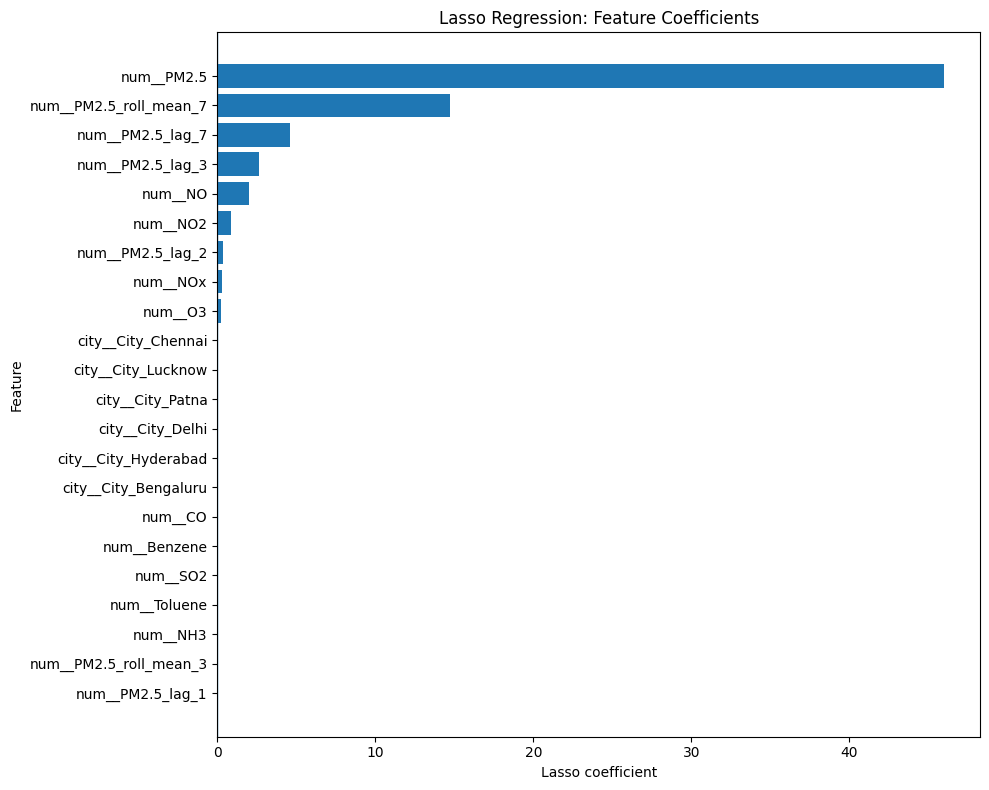

Saved plot to: /content/drive/MyDrive/PM25_project/figures/lasso_coefficients.png
Number of coefficients: 22
Coefficients exactly zero: 13


In [ ]:

import matplotlib.pyplot as plt

# Extract the fitted preprocessing and Lasso model
fitted_preprocessor = best_lasso.named_steps["preprocessor"]
fitted_lasso = best_lasso.named_steps["model"]

# Get feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = fitted_lasso.coef_

# Create a coefficient table
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by coefficient for easier interpretation
coef_df = coef_df.sort_values("Coefficient")

# Plot coefficients
plt.figure(figsize=(10, 8))
plt.barh(coef_df["Feature"], coef_df["Coefficient"])
plt.axvline(0, linewidth=1)
plt.xlabel("Lasso coefficient")
plt.ylabel("Feature")
plt.title("Lasso Regression: Feature Coefficients")
plt.tight_layout()

# Save the figure
FIGURE_DIR = PROJECT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

plot_path = FIGURE_DIR / "lasso_coefficients.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved plot to:", plot_path)
print("Number of coefficients:", len(coefficients))
print("Coefficients exactly zero:", int(np.sum(coefficients == 0)))


In [ ]:

results_path = OUTPUT_DIR / "linear_models_validation.csv"
plot_path = PROJECT_DIR / "figures" / "lasso_coefficients.png"

print("Validation results saved:", results_path.exists())
print("Coefficient plot saved:", plot_path.exists())

print("\nValidation results:")
print(pd.read_csv(results_path).round(4).to_string(index=False))

print("\nNonzero Lasso coefficients:")
print(
    coef_df.loc[coef_df["Coefficient"].abs() > 1e-8]
    .sort_values("Coefficient", key=abs, ascending=False)
    .round(4)
    .to_string(index=False)
)


Validation results saved: True
Coefficient plot saved: True

Validation results:
               Model     MAE    RMSE  Skill_vs_persistence
Persistence baseline 16.3761 29.8570                0.0000
         Lasso (raw) 16.4903 28.5200               -0.0070
           OLS (raw) 16.5712 28.5645               -0.0119
         Ridge (raw) 16.6233 28.6155               -0.0151
       Ridge (log1p) 22.6314 46.8102               -0.3820
         OLS (log1p) 22.6464 47.4991               -0.3829
       Lasso (log1p) 42.7048 67.0370               -1.6078

Nonzero Lasso coefficients:
               Feature  Coefficient
            num__PM2.5      45.9675
num__PM2.5_roll_mean_7      14.7282
      num__PM2.5_lag_7       4.5670
      num__PM2.5_lag_3       2.6588
               num__NO       2.0075
              num__NO2       0.8399
      num__PM2.5_lag_2       0.3263
              num__NOx       0.3102
               num__O3       0.2176


In [ ]:

from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error
from time import perf_counter

# Build SVR pipeline
svr_pipeline = Pipeline(steps=[
    ("preprocessor", make_preprocessor()),
    ("model", SVR(kernel="rbf", epsilon=0.1))
])

# Hyperparameter grid specified in the project plan
svr_param_grid = {
    "model__C": [1, 10, 100],
    "model__gamma": ["scale", 0.01, 0.1]
}

svr_search = GridSearchCV(
    estimator=svr_pipeline,
    param_grid=svr_param_grid,
    scoring="neg_mean_absolute_error",
    cv=TimeSeriesSplit(n_splits=5),
    n_jobs=-1,
    verbose=1
)

print("SVR pipeline and parameter grid are ready.")
print("Parameter combinations:", 9)
print("Cross-validation fits expected:", 45)


SVR pipeline and parameter grid are ready.
Parameter combinations: 9
Cross-validation fits expected: 45


In [ ]:

start_time = perf_counter()

svr_search.fit(X_train, y_train)

svr_training_seconds = perf_counter() - start_time

best_svr = svr_search.best_estimator_

print("\nBest SVR parameters:", svr_search.best_params_)
print("Best training CV MAE:", round(-svr_search.best_score_, 4))
print(f"Search training time: {svr_training_seconds / 60:.2f} minutes")



Fitting 5 folds for each of 9 candidates, totalling 45 fits

Best SVR parameters: {'model__C': 100, 'model__gamma': 0.01}
Best training CV MAE: 20.9689
Search training time: 1.56 minutes


In [ ]:

# Measure validation prediction time
prediction_start = perf_counter()

svr_val_pred = best_svr.predict(X_val)

svr_prediction_seconds = perf_counter() - prediction_start

# Preliminary validation metrics on all validation rows
svr_mae = mean_absolute_error(y_val, svr_val_pred)
svr_rmse = np.sqrt(mean_squared_error(y_val, svr_val_pred))

print("SVR Validation Results")
print("----------------------")
print(f"MAE: {svr_mae:.4f}")
print(f"RMSE: {svr_rmse:.4f}")
print(f"Prediction time: {svr_prediction_seconds:.4f} seconds")
print(f"Training search time: {svr_training_seconds / 60:.2f} minutes")


SVR Validation Results
----------------------
MAE: 15.6591
RMSE: 27.6210
Prediction time: 2.4557 seconds
Training search time: 1.56 minutes


In [ ]:

# Evaluate all models on the same baseline-comparable validation rows
common_mask = val_df["baseline_comparable"].astype(bool).to_numpy()
y_common = y_val.to_numpy()[common_mask]

persistence_pred = val_df.loc[
    common_mask, "PM2.5"
].to_numpy()

# Predictions from models already fitted
common_predictions = {
    "Persistence baseline": persistence_pred,
    "OLS (raw)": ols_val_pred[common_mask],
    "Ridge (raw)": ridge_val_pred[common_mask],
    "Lasso (raw)": lasso_val_pred[common_mask],
    "SVR (RBF)": svr_val_pred[common_mask]
}

persistence_mae = mean_absolute_error(y_common, persistence_pred)

comparison_day9 = []

for name, pred in common_predictions.items():
    mae = mean_absolute_error(y_common, pred)
    rmse = np.sqrt(mean_squared_error(y_common, pred))
    skill = 1 - mae / persistence_mae

    comparison_day9.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "Skill_vs_persistence": skill
    })

comparison_day9_df = pd.DataFrame(comparison_day9)
comparison_day9_df = comparison_day9_df.sort_values("MAE")

print("Common validation rows:", len(y_common))
print(comparison_day9_df.round(4).to_string(index=False))


Common validation rows: 2182
               Model     MAE    RMSE  Skill_vs_persistence
           SVR (RBF) 15.6688 27.6487                0.0432
Persistence baseline 16.3761 29.8570                0.0000
         Lasso (raw) 16.4903 28.5200               -0.0070
           OLS (raw) 16.5712 28.5645               -0.0119
         Ridge (raw) 16.6233 28.6155               -0.0151


In [ ]:

# Save the updated model comparison
results_path = OUTPUT_DIR / "model_comparison_validation.csv"

comparison_day9_df.to_csv(results_path, index=False)

print("Saved to:", results_path)
print("File exists:", results_path.exists())

# Save SVR timing and tuning details separately
svr_details = pd.DataFrame([{
    "Model": "SVR (RBF)",
    "Best_C": svr_search.best_params_["model__C"],
    "Best_gamma": svr_search.best_params_["model__gamma"],
    "Epsilon": 0.1,
    "Training_search_minutes": svr_training_seconds / 60,
    "Validation_prediction_seconds": svr_prediction_seconds,
    "Training_CV_MAE": -svr_search.best_score_
}])

svr_details_path = OUTPUT_DIR / "svr_training_details.csv"
svr_details.to_csv(svr_details_path, index=False)

print("SVR details saved:", svr_details_path.exists())


Saved to: /content/drive/MyDrive/PM25_project/outputs/model_comparison_validation.csv
File exists: True
SVR details saved: True


In [ ]:

results_path = OUTPUT_DIR / "model_comparison_validation.csv"
svr_details_path = OUTPUT_DIR / "svr_training_details.csv"

print("Model comparison saved:", results_path.exists())
print("SVR training details saved:", svr_details_path.exists())

if results_path.exists():
    print("\nSaved model comparison:")
    print(
        pd.read_csv(results_path)
        .round(4)
        .to_string(index=False)
    )

if svr_details_path.exists():
    print("\nSaved SVR details:")
    print(
        pd.read_csv(svr_details_path)
        .round(4)
        .to_string(index=False)
    )



Model comparison saved: True
SVR training details saved: True

Saved model comparison:
               Model     MAE    RMSE  Skill_vs_persistence
           SVR (RBF) 15.6688 27.6487                0.0432
Persistence baseline 16.3761 29.8570                0.0000
         Lasso (raw) 16.4903 28.5200               -0.0070
           OLS (raw) 16.5712 28.5645               -0.0119
         Ridge (raw) 16.6233 28.6155               -0.0151

Saved SVR details:
    Model  Best_C  Best_gamma  Epsilon  Training_search_minutes  Validation_prediction_seconds  Training_CV_MAE
SVR (RBF)     100        0.01      0.1                   1.5633                         2.4557          20.9689


In [ ]:

from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error
from time import perf_counter
import numpy as np
import pandas as pd

# Random Forest pipeline
rf_pipeline = Pipeline(steps=[
    ("preprocessor", make_preprocessor()),
    ("model", RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

# HistGradientBoosting pipeline
hgb_pipeline = Pipeline(steps=[
    ("preprocessor", make_preprocessor()),
    ("model", HistGradientBoostingRegressor(
        random_state=42
    ))
])

print("Random Forest and HistGradientBoosting pipelines are ready.")
print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))


Random Forest and HistGradientBoosting pipelines are ready.
Training rows: 7751
Validation rows: 2188


In [ ]:

rf_param_grid = {
    "model__max_depth": [8, 16, None],
    "model__min_samples_leaf": [1, 5, 10]
}

rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    scoring="neg_mean_absolute_error",
    cv=TimeSeriesSplit(n_splits=5),
    n_jobs=-1,
    verbose=1
)

print("Random Forest tuning grid:", rf_param_grid)
print("Parameter combinations:", len(rf_search.param_grid["model__max_depth"]) *
      len(rf_search.param_grid["model__min_samples_leaf"]))
print("Cross-validation folds: 5")
print("Total fits:", 9 * 5)


Random Forest tuning grid: {'model__max_depth': [8, 16, None], 'model__min_samples_leaf': [1, 5, 10]}
Parameter combinations: 9
Cross-validation folds: 5
Total fits: 45


In [ ]:

start_time = perf_counter()

rf_search.fit(X_train, y_train)

rf_training_seconds = perf_counter() - start_time

best_rf = rf_search.best_estimator_

print("Best Random Forest parameters:", rf_search.best_params_)
print("Best cross-validation MAE:", round(-rf_search.best_score_, 4))
print("Total tuning time (minutes):", round(rf_training_seconds / 60, 2))


Fitting 5 folds for each of 9 candidates, totalling 45 fits
Best Random Forest parameters: {'model__max_depth': 8, 'model__min_samples_leaf': 10}
Best cross-validation MAE: 20.4557
Total tuning time (minutes): 15.57


In [ ]:

prediction_start = perf_counter()

rf_val_pred = best_rf.predict(X_val)

rf_prediction_seconds = perf_counter() - prediction_start

rf_mae = mean_absolute_error(y_val, rf_val_pred)
rf_rmse = np.sqrt(mean_squared_error(y_val, rf_val_pred))

print("Random Forest validation MAE:", round(rf_mae, 4))
print("Random Forest validation RMSE:", round(rf_rmse, 4))
print("Validation prediction time (seconds):",
      round(rf_prediction_seconds, 4))


Random Forest validation MAE: 15.8373
Random Forest validation RMSE: 27.5707
Validation prediction time (seconds): 0.1274


In [ ]:

hgb_param_grid = {
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [3, 6]
}

hgb_search = GridSearchCV(
    estimator=hgb_pipeline,
    param_grid=hgb_param_grid,
    scoring="neg_mean_absolute_error",
    cv=TimeSeriesSplit(n_splits=5),
    n_jobs=-1,
    verbose=1
)

print("HistGradientBoosting tuning grid:", hgb_param_grid)
print("Parameter combinations:", 4)
print("Cross-validation folds:", 5)
print("Total fits:", 20)


HistGradientBoosting tuning grid: {'model__learning_rate': [0.05, 0.1], 'model__max_depth': [3, 6]}
Parameter combinations: 4
Cross-validation folds: 5
Total fits: 20


In [ ]:

start_time = perf_counter()

hgb_search.fit(X_train, y_train)

hgb_training_seconds = perf_counter() - start_time

best_hgb = hgb_search.best_estimator_

print("Best HistGradientBoosting parameters:",
      hgb_search.best_params_)

print("Best cross-validation MAE:",
      round(-hgb_search.best_score_, 4))

print("Total tuning time (minutes):",
      round(hgb_training_seconds / 60, 2))


Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best HistGradientBoosting parameters: {'model__learning_rate': 0.05, 'model__max_depth': 3}
Best cross-validation MAE: 20.9332
Total tuning time (minutes): 0.07


In [ ]:

prediction_start = perf_counter()

hgb_val_pred = best_hgb.predict(X_val)

hgb_prediction_seconds = perf_counter() - prediction_start

hgb_mae = mean_absolute_error(y_val, hgb_val_pred)
hgb_rmse = np.sqrt(mean_squared_error(y_val, hgb_val_pred))

print("HistGradientBoosting validation MAE:",
      round(hgb_mae, 4))

print("HistGradientBoosting validation RMSE:",
      round(hgb_rmse, 4))

print("Validation prediction time (seconds):",
      round(hgb_prediction_seconds, 4))


HistGradientBoosting validation MAE: 16.1886
HistGradientBoosting validation RMSE: 27.7657
Validation prediction time (seconds): 0.0246


In [ ]:

common_mask = val_df["baseline_comparable"].astype(bool).to_numpy()

y_common = y_val.to_numpy()[common_mask]

persistence_pred = (
    val_df.loc[common_mask, "PM2.5"].to_numpy()
)

common_predictions = {
    "Persistence baseline": persistence_pred,
    "OLS (raw)": ols_val_pred[common_mask],
    "Ridge (raw)": ridge_val_pred[common_mask],
    "Lasso (raw)": lasso_val_pred[common_mask],
    "SVR (RBF)": svr_val_pred[common_mask],
    "Random Forest": rf_val_pred[common_mask],
    "HistGradientBoosting": hgb_val_pred[common_mask]
}

persistence_mae = mean_absolute_error(
    y_common, persistence_pred
)

comparison_day10 = []

for name, pred in common_predictions.items():
    mae = mean_absolute_error(y_common, pred)
    rmse = np.sqrt(mean_squared_error(y_common, pred))
    skill = 1 - mae / persistence_mae

    comparison_day10.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "Skill_vs_persistence": skill
    })

comparison_day10_df = (
    pd.DataFrame(comparison_day10)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("Common validation rows:", len(y_common))
print(comparison_day10_df.round(4).to_string(index=False))


Common validation rows: 2182
               Model     MAE    RMSE  Skill_vs_persistence
           SVR (RBF) 15.6688 27.6487                0.0432
       Random Forest 15.8567 27.6034                0.0317
HistGradientBoosting 16.2157 27.8004                0.0098
Persistence baseline 16.3761 29.8570                0.0000
         Lasso (raw) 16.4903 28.5200               -0.0070
           OLS (raw) 16.5712 28.5645               -0.0119
         Ridge (raw) 16.6233 28.6155               -0.0151


In [ ]:

comparison_path = OUTPUT_DIR / "model_comparison_validation.csv"

comparison_day10_df.to_csv(
    comparison_path,
    index=False
)

print("Saved to:", comparison_path)
print("File exists:", comparison_path.exists())

print("\nFinal validation comparison:")
print(
    pd.read_csv(comparison_path)
    .round(4)
    .to_string(index=False)
)


Saved to: /content/drive/MyDrive/PM25_project/outputs/model_comparison_validation.csv
File exists: True

Final validation comparison:
               Model     MAE    RMSE  Skill_vs_persistence
           SVR (RBF) 15.6688 27.6487                0.0432
       Random Forest 15.8567 27.6034                0.0317
HistGradientBoosting 16.2157 27.8004                0.0098
Persistence baseline 16.3761 29.8570                0.0000
         Lasso (raw) 16.4903 28.5200               -0.0070
           OLS (raw) 16.5712 28.5645               -0.0119
         Ridge (raw) 16.6233 28.6155               -0.0151


**DAY10**

In [ ]:

# Extract the fitted Random Forest model
rf_fitted_model = best_rf.named_steps["model"]

# Get feature names after preprocessing
feature_names = (
    best_rf.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Create feature importance dataframe
rf_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_fitted_model.feature_importances_
})

rf_importance_df = rf_importance_df.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

print("Top 15 Random Forest features:")
print(rf_importance_df.head(15).round(4).to_string(index=False))


Top 15 Random Forest features:
               Feature  Importance
            num__PM2.5      0.8940
num__PM2.5_roll_mean_3      0.0266
num__PM2.5_roll_mean_7      0.0152
               num__CO      0.0102
      num__PM2.5_lag_3      0.0096
      num__PM2.5_lag_7      0.0076
      num__PM2.5_lag_1      0.0068
               num__NO      0.0046
      num__PM2.5_lag_2      0.0045
              num__NO2      0.0044
               num__O3      0.0038
              num__NOx      0.0034
          num__Toluene      0.0027
              num__SO2      0.0027
          num__Benzene      0.0016


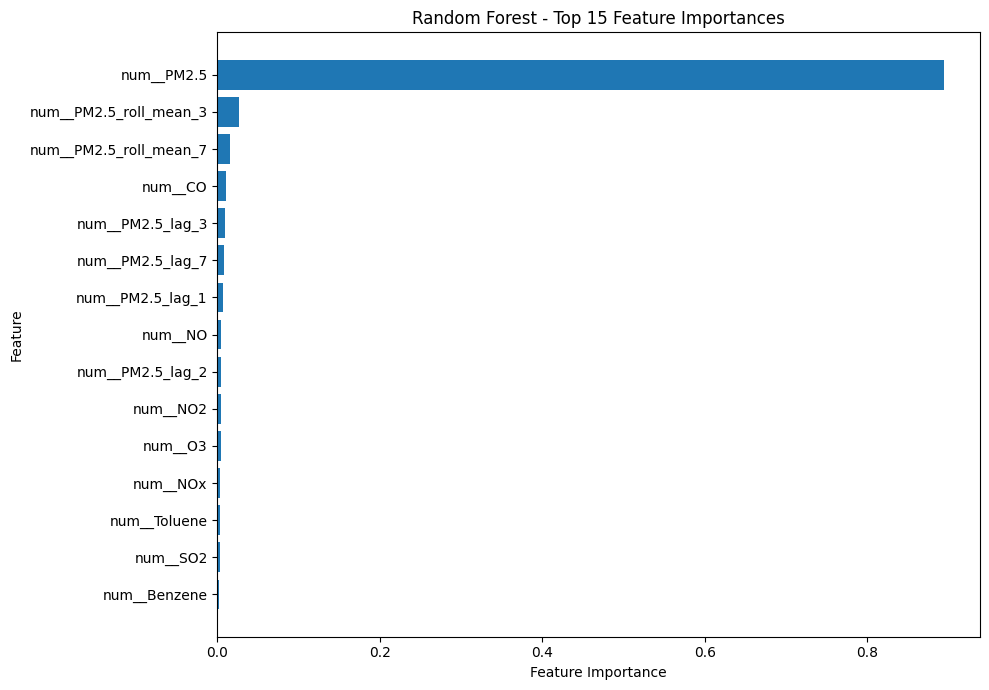

Plot saved to: /content/drive/MyDrive/PM25_project/figures/random_forest_feature_importance.png
File exists: True


In [ ]:

import matplotlib.pyplot as plt

top_features = rf_importance_df.head(15).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest - Top 15 Feature Importances")

plt.tight_layout()

rf_importance_path = FIGURE_DIR / "random_forest_feature_importance.png"

plt.savefig(
    rf_importance_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Plot saved to:", rf_importance_path)
print("File exists:", rf_importance_path.exists())


In [ ]:

comparison_path = OUTPUT_DIR / "model_comparison_validation.csv"
rf_importance_path = FIGURE_DIR / "random_forest_feature_importance.png"

print("Model comparison saved:", comparison_path.exists())
print("Random Forest feature importance plot saved:",
      rf_importance_path.exists())

print("\nFinal model comparison:")
print(
    pd.read_csv(comparison_path)
    .round(4)
    .to_string(index=False)
)

print("\nRandom Forest training time (minutes):",
      round(rf_training_seconds / 60, 2))

print("HistGradientBoosting training time (minutes):",
      round(hgb_training_seconds / 60, 2))


Model comparison saved: True
Random Forest feature importance plot saved: True

Final model comparison:
               Model     MAE    RMSE  Skill_vs_persistence
           SVR (RBF) 15.6688 27.6487                0.0432
       Random Forest 15.8567 27.6034                0.0317
HistGradientBoosting 16.2157 27.8004                0.0098
Persistence baseline 16.3761 29.8570                0.0000
         Lasso (raw) 16.4903 28.5200               -0.0070
           OLS (raw) 16.5712 28.5645               -0.0119
         Ridge (raw) 16.6233 28.6155               -0.0151

Random Forest training time (minutes): 15.57
HistGradientBoosting training time (minutes): 0.07


**DAY11**

In [ ]:

# Check whether the 7-day mean baseline predictions exist

print("7-day mean prediction variable available:",
      "mean7_val_pred" in globals())

print("Validation comparison dataframe available:",
      "comparison_day10_df" in globals())

print("Validation rows:", len(val_df))
print("Common validation rows:",
      int(val_df["baseline_comparable"].sum()))


7-day mean prediction variable available: False
Validation comparison dataframe available: True
Validation rows: 2188
Common validation rows: 2182


In [ ]:

# Generate 7-day mean baseline predictions
mean7_val_pred = val_df["PM2.5_roll_mean_7"].to_numpy()

# Evaluate only on common validation rows
common_mask = val_df["baseline_comparable"].astype(bool).to_numpy()

y_common = y_val.to_numpy()[common_mask]
mean7_common_pred = mean7_val_pred[common_mask]

mean7_mae = mean_absolute_error(y_common, mean7_common_pred)
mean7_rmse = np.sqrt(
    mean_squared_error(y_common, mean7_common_pred)
)

persistence_mae = mean_absolute_error(
    y_common,
    val_df.loc[common_mask, "PM2.5"].to_numpy()
)

mean7_skill = 1 - mean7_mae / persistence_mae

print("7-day mean baseline results")
print("MAE:", round(mean7_mae, 4))
print("RMSE:", round(mean7_rmse, 4))
print("Skill vs persistence:", round(mean7_skill, 4))


7-day mean baseline results
MAE: 21.2331
RMSE: 37.1337
Skill vs persistence: -0.2966


In [ ]:
# Create the 7-day mean baseline row
mean7_row = pd.DataFrame([{
    "Model": "7-day mean baseline",
    "MAE": mean7_mae,
    "RMSE": mean7_rmse,
    "Skill_vs_persistence": mean7_skill
}])

# Add it to the Day 10 comparison table
comparison_day11_df = pd.concat(
    [
        comparison_day10_df[
            comparison_day10_df["Model"] != "7-day mean baseline"
        ],
        mean7_row
    ],
    ignore_index=True
)

# Sort models by MAE (lower is better)
comparison_day11_df = comparison_day11_df.sort_values(
    by="MAE"
).reset_index(drop=True)

display(comparison_day11_df.round(4))

# Save the updated comparison table
comparison_day11_df.to_csv(
    "/content/drive/MyDrive/PM25_project/outputs/model_comparison_validation.csv",
    index=False
)

print("Updated validation comparison saved successfully.")

,Model,MAE,RMSE,Skill_vs_persistence
0,SVR (RBF),15.6688,27.6487,0.0432
1,Random Forest,15.8567,27.6034,0.0317
2,HistGradientBoosting,16.2157,27.8004,0.0098
3,Persistence baseline,16.3761,29.8570,0.0000
4,Lasso (raw),16.4903,28.5200,-0.0070
5,OLS (raw),16.5712,28.5645,-0.0119
6,Ridge (raw),16.6233,28.6155,-0.0151
7,7-day mean baseline,21.2331,37.1337,-0.2966


Updated validation comparison saved successfully.


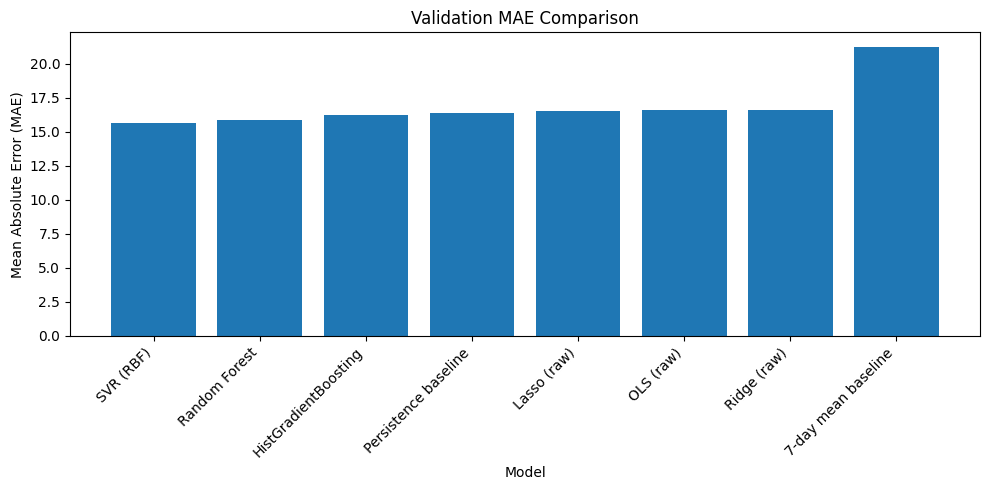

MAE comparison chart saved successfully.


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    comparison_day11_df["Model"],
    comparison_day11_df["MAE"]
)

plt.title("Validation MAE Comparison")
plt.xlabel("Model")
plt.ylabel("Mean Absolute Error (MAE)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/PM25_project/figures/validation_mae_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("MAE comparison chart saved successfully.")

In [ ]:
# Count validation observations for each city in 2019
city_2019_counts = (
    val_df[
        (val_df["Target_Date"].dt.year == 2019)
    ]
    .groupby("City")
    .size()
    .sort_values(ascending=False)
)

display(city_2019_counts)

,0
City,
Bengaluru,365
Chennai,365
Delhi,365
Hyderabad,365
Lucknow,365
Patna,363


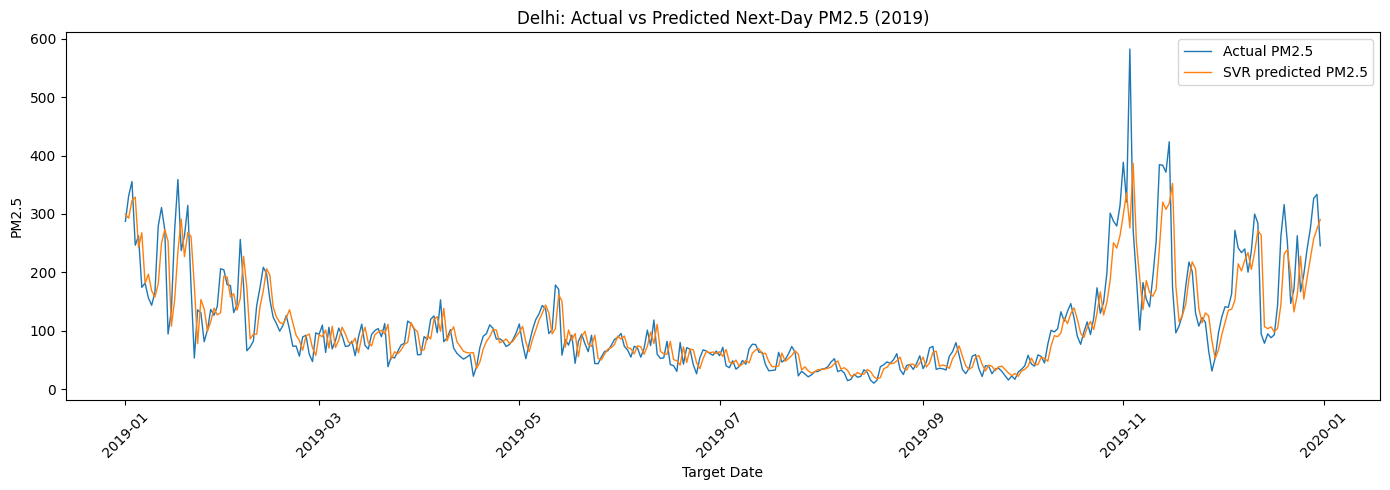

Delhi actual vs predicted chart saved successfully.
Number of observations: 365


In [ ]:
# Select Delhi observations whose target date falls in 2019
delhi_mask = (
    (val_df["City"] == "Delhi") &
    (val_df["Target_Date"].dt.year == 2019)
).to_numpy()

# Extract actual and predicted values
delhi_dates = val_df.loc[delhi_mask, "Target_Date"]
delhi_actual = y_val.to_numpy()[delhi_mask]
delhi_predicted = svr_val_pred[delhi_mask]

# Plot
plt.figure(figsize=(14, 5))

plt.plot(
    delhi_dates,
    delhi_actual,
    label="Actual PM2.5",
    linewidth=1
)

plt.plot(
    delhi_dates,
    delhi_predicted,
    label="SVR predicted PM2.5",
    linewidth=1
)

plt.title("Delhi: Actual vs Predicted Next-Day PM2.5 (2019)")
plt.xlabel("Target Date")
plt.ylabel("PM2.5")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/PM25_project/figures/delhi_actual_vs_predicted_2019.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Delhi actual vs predicted chart saved successfully.")
print("Number of observations:", len(delhi_actual))

In [ ]:
best_mae = comparison_day11_df["MAE"].min()
threshold_2pct = best_mae * 1.02

comparison_day11_df["MAE_gap_pct"] = (
    (comparison_day11_df["MAE"] / best_mae - 1) * 100
)

comparison_day11_df["Within_2_percent"] = (
    comparison_day11_df["MAE"] <= threshold_2pct
)

display(comparison_day11_df.round(4))

print("Best MAE:", round(best_mae, 4))
print("2% threshold:", round(threshold_2pct, 4))

,Model,MAE,RMSE,Skill_vs_persistence,MAE_gap_pct,Within_2_percent
0,SVR (RBF),15.6688,27.6487,0.0432,0.0000,True
1,Random Forest,15.8567,27.6034,0.0317,1.1991,True
2,HistGradientBoosting,16.2157,27.8004,0.0098,3.4904,False
3,Persistence baseline,16.3761,29.8570,0.0000,4.5136,False
4,Lasso (raw),16.4903,28.5200,-0.0070,5.2429,False
5,OLS (raw),16.5712,28.5645,-0.0119,5.7592,False
6,Ridge (raw),16.6233,28.6155,-0.0151,6.0918,False
7,7-day mean baseline,21.2331,37.1337,-0.2966,35.5119,False


Best MAE: 15.6688
2% threshold: 15.9822


In [ ]:
chosen_model_text = """
Final Regression Model: SVR (RBF)

Selected model: Support Vector Regression with an RBF kernel.

Selected hyperparameters:
- C = 100
- gamma = 0.01
- epsilon = 0.1

Reason for selection:
SVR achieved the lowest validation MAE of 15.6688 and
validation RMSE of 27.6487. It improved MAE by approximately
4.32% compared with the persistence baseline.

Random Forest was within 2% of the best MAE, but it uses
an ensemble of 300 decision trees and is not clearly a
simpler alternative to RBF-SVR. The simpler linear models
were more than 2% away from the best MAE.

Random Forest remains a close alternative, with slightly
lower RMSE and faster prediction time.

The test set has not been used for model selection.
"""

path = (
    "/content/drive/MyDrive/PM25_project/outputs/"
    "chosen_regression_model.txt"
)

with open(path, "w") as f:
    f.write(chosen_model_text)

print("Model-selection decision saved:", path)

Model-selection decision saved: /content/drive/MyDrive/PM25_project/outputs/chosen_regression_model.txt


In [ ]:
methods_text = """
# Regression Methods and Baselines

## 1. Persistence Baseline
Core idea: Predict tomorrow's PM2.5 using today's PM2.5 value.
Assumptions: Today's pollution level is a useful indicator of tomorrow's level.
Why included: It is a simple reference point that every machine learning model should try to outperform.

## 2. 7-Day Mean Baseline
Core idea: Predict tomorrow's PM2.5 using the average PM2.5 of the previous seven days.
Assumptions: Recent average pollution represents the near-future pollution level.
Why included: It provides a simple way to compare short-term averaging against persistence.

## 3. Ordinary Least Squares (OLS)
Core idea: Fits a linear relationship between input features and next-day PM2.5 by minimizing squared prediction errors.
Assumptions: The relationship between features and the target is approximately linear.
Why included: It provides an interpretable linear benchmark for understanding how current pollution and other pollutants relate to the prediction.

## 4. Ridge Regression
Core idea: Linear regression with an L2 penalty that discourages excessively large coefficients.
Assumptions: The relationship is approximately linear; regularization helps when input features are correlated.
Why included: Pollutant measurements can be correlated, so Ridge can reduce coefficient instability and overfitting.

## 5. Lasso Regression
Core idea: Linear regression with an L1 penalty that can shrink some coefficients to zero.
Assumptions: A relatively small subset of features may explain much of the target variation.
Why included: It performs regularization and can provide a simpler feature representation.

## 6. Support Vector Regression (SVR - RBF)
Core idea: Uses an RBF kernel to learn nonlinear relationships while controlling prediction errors within an epsilon-insensitive margin.
Assumptions: Similar observations in feature space tend to have related target values; the relationship need not be linear.
Why included: It can capture nonlinear pollution patterns that linear regression may miss.

## 7. Random Forest Regression
Core idea: Combines predictions from many decision trees trained on different samples and feature subsets.
Assumptions: Useful patterns can be represented through decision-tree splits; a linear relationship is not required.
Why included: It captures nonlinear relationships and feature interactions and provides a feature-importance estimate.

## 8. Histogram-Based Gradient Boosting
Core idea: Builds decision trees sequentially, with each new tree correcting errors made by the previous ensemble.
Assumptions: The target contains patterns that can be learned through successive tree-based improvements.
Why included: It provides an efficient nonlinear boosting method for tabular data.
"""

methods_path = (
    "/content/drive/MyDrive/PM25_project/outputs/"
    "regression_methods.md"
)

with open(methods_path, "w") as f:
    f.write(methods_text)

print("Methods explanations saved:", methods_path)

Methods explanations saved: /content/drive/MyDrive/PM25_project/outputs/regression_methods.md


In [ ]:
import os

base = "/content/drive/MyDrive/PM25_project"

files_to_check = [
    "outputs/model_comparison_validation.csv",
    "outputs/chosen_regression_model.txt",
    "outputs/regression_methods.md",
    "figures/validation_mae_comparison.png",
    "figures/delhi_actual_vs_predicted_2019.png"
]

print("DAY 11 FILE VERIFICATION\n")

for file in files_to_check:
    full_path = os.path.join(base, file)
    print(
        ("FOUND   " if os.path.exists(full_path) else "MISSING "),
        file
    )

DAY 11 FILE VERIFICATION

FOUND    outputs/model_comparison_validation.csv
FOUND    outputs/chosen_regression_model.txt
FOUND    outputs/regression_methods.md
FOUND    figures/validation_mae_comparison.png
FOUND    figures/delhi_actual_vs_predicted_2019.png


**DAY12**

In [ ]:
print("Available classification-related columns:")

print([
    col for col in model_df.columns
    if "poor" in col.lower() or "target" in col.lower()
])

print("\nDataset shape:", model_df.shape)

print("\nSplit counts:")
print(model_df["Split"].value_counts())

Available classification-related columns:
['Target_Date']

Dataset shape: (11037, 22)

Split counts:
Split
train         7751
validation    2188
test          1098
Name: count, dtype: int64


In [ ]:
# Create the next-day Poor-day classification target
model_df["y_poor"] = (
    model_df["PM2.5_next_day"] > 90
).astype("Int64")

# Check class distribution in training and validation only
for split in ["train", "validation"]:
    subset = model_df[model_df["Split"] == split]

    print(f"\n{split.upper()}")
    print("Class counts:")
    print(subset["y_poor"].value_counts(dropna=False).sort_index())

    print("\nClass percentages:")
    print(
        (subset["y_poor"].value_counts(normalize=True) * 100)
        .sort_index()
        .round(2)
    )


TRAIN
Class counts:
y_poor
0    5451
1    2300
Name: count, dtype: Int64

Class percentages:
y_poor
0    70.33
1    29.67
Name: proportion, dtype: Float64

VALIDATION
Class counts:
y_poor
0    1695
1     493
Name: count, dtype: Int64

Class percentages:
y_poor
0    77.47
1    22.53
Name: proportion, dtype: Float64


In [ ]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

# Select validation data
val_cls = model_df[model_df["Split"] == "validation"].copy()

# Actual next-day classification label
y_val_cls = (val_cls["PM2.5_next_day"] > 90).astype(int)

# Baseline prediction using today's PM2.5
baseline_val_pred = (val_cls["PM2.5"] > 90).astype(int)

print("Validation classification baseline")
print("Rows evaluated:", len(val_cls))
print("Precision:", precision_score(y_val_cls, baseline_val_pred))
print("Recall:", recall_score(y_val_cls, baseline_val_pred))
print("F1:", f1_score(y_val_cls, baseline_val_pred))
print("PR-AUC:", average_precision_score(y_val_cls, baseline_val_pred))

print("\nConfusion matrix:")
print(confusion_matrix(y_val_cls, baseline_val_pred))

Validation classification baseline
Rows evaluated: 2188
Precision: 0.8397565922920892
Recall: 0.8397565922920892
F1: 0.8397565922920892
PR-AUC: 0.7412971672047863

Confusion matrix:
[[1616   79]
 [  79  414]]


In [ ]:
# Create binary classification targets
train_cls = model_df[model_df["Split"] == "train"].copy()
val_cls = model_df[model_df["Split"] == "validation"].copy()

y_train_cls = (train_cls["PM2.5_next_day"] > 90).astype(int)
y_val_cls = (val_cls["PM2.5_next_day"] > 90).astype(int)

# Use the existing feature lists from regression
X_train_cls = train_cls[numeric_features + categorical_features]
X_val_cls = val_cls[numeric_features + categorical_features]

print("Training features:", X_train_cls.shape)
print("Validation features:", X_val_cls.shape)

print("\nTraining target distribution:")
print(y_train_cls.value_counts())

print("\nValidation target distribution:")
print(y_val_cls.value_counts())

print("\nMissing values in training features:", X_train_cls.isna().sum().sum())
print("Missing values in validation features:", X_val_cls.isna().sum().sum())

Training features: (7751, 17)
Validation features: (2188, 17)

Training target distribution:
PM2.5_next_day
0    5451
1    2300
Name: count, dtype: int64

Validation target distribution:
PM2.5_next_day
0    1695
1     493
Name: count, dtype: int64

Missing values in training features: 5217
Missing values in validation features: 450


In [ ]:
from sklearn.linear_model import LogisticRegression

# Build the classification pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", make_preprocessor()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight=None,
        random_state=42
    ))
])

# Train
logistic_model.fit(X_train_cls, y_train_cls)

# Predict class labels and probabilities
logistic_val_pred = logistic_model.predict(X_val_cls)
logistic_val_prob = logistic_model.predict_proba(X_val_cls)[:, 1]

print("Logistic Regression training completed.")
print("Predictions generated:", len(logistic_val_pred))
print("Probability range:",
      logistic_val_prob.min(), "to", logistic_val_prob.max())

Logistic Regression training completed.
Predictions generated: 2188
Probability range: 0.0028182956148819194 to 0.9999999815077699


In [ ]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

print("LOGISTIC REGRESSION — VALIDATION RESULTS")

print("Precision:", precision_score(y_val_cls, logistic_val_pred))
print("Recall:", recall_score(y_val_cls, logistic_val_pred))
print("F1-score:", f1_score(y_val_cls, logistic_val_pred))
print("PR-AUC:", average_precision_score(y_val_cls, logistic_val_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_cls, logistic_val_pred))

print("\nClassification Report:")
print(classification_report(y_val_cls, logistic_val_pred))

LOGISTIC REGRESSION — VALIDATION RESULTS
Precision: 0.8810068649885584
Recall: 0.7809330628803245
F1-score: 0.8279569892473119
PR-AUC: 0.9239514587879819

Confusion Matrix:
[[1643   52]
 [ 108  385]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.97      0.95      1695
           1       0.88      0.78      0.83       493

    accuracy                           0.93      2188
   macro avg       0.91      0.88      0.89      2188
weighted avg       0.93      0.93      0.93      2188



In [ ]:
logistic_results = pd.DataFrame([{
    "Model": "Logistic Regression",
    "Threshold": 0.5,
    "Precision": precision_score(y_val_cls, logistic_val_pred),
    "Recall": recall_score(y_val_cls, logistic_val_pred),
    "F1": f1_score(y_val_cls, logistic_val_pred),
    "PR_AUC": average_precision_score(y_val_cls, logistic_val_prob)
}])

print(logistic_results)

                 Model  Threshold  Precision    Recall        F1    PR_AUC
0  Logistic Regression        0.5   0.881007  0.780933  0.827957  0.923951


In [ ]:
threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:

    predictions = (logistic_val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val_cls, predictions),
        "Recall": recall_score(y_val_cls, predictions),
        "F1": f1_score(y_val_cls, predictions)
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4).to_string(index=False))

 Threshold  Precision  Recall     F1
      0.30     0.7897  0.8986 0.8406
      0.35     0.8166  0.8580 0.8368
      0.40     0.8418  0.8418 0.8418
      0.45     0.8615  0.8073 0.8335
      0.50     0.8810  0.7809 0.8280
      0.55     0.8988  0.7566 0.8216
      0.60     0.9148  0.7404 0.8184
      0.65     0.9318  0.7201 0.8124
      0.70     0.9425  0.6978 0.8019


In [ ]:
best_threshold = 0.40

logistic_tuned_pred = (
    logistic_val_prob >= best_threshold
).astype(int)

print("Selected threshold:", best_threshold)
print("Precision:", precision_score(y_val_cls, logistic_tuned_pred))
print("Recall:", recall_score(y_val_cls, logistic_tuned_pred))
print("F1:", f1_score(y_val_cls, logistic_tuned_pred))
print("\nConfusion matrix:")
print(confusion_matrix(y_val_cls, logistic_tuned_pred))

Selected threshold: 0.4
Precision: 0.8417849898580122
Recall: 0.8417849898580122
F1: 0.8417849898580122

Confusion matrix:
[[1617   78]
 [  78  415]]


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_cls_pipeline = Pipeline(steps=[
    ("preprocessor", make_preprocessor()),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=10,
        class_weight=None,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the classifier
rf_cls_pipeline.fit(X_train_cls, y_train_cls)

# Generate validation predictions
rf_val_pred = rf_cls_pipeline.predict(X_val_cls)
rf_val_prob = rf_cls_pipeline.predict_proba(X_val_cls)[:, 1]

print("Random Forest Classifier training completed.")
print("Predictions generated:", len(rf_val_pred))
print("Probability range:", rf_val_prob.min(), "to", rf_val_prob.max())

Random Forest Classifier training completed.
Predictions generated: 2188
Probability range: 0.006647149072930905 to 0.9977710590841016


In [ ]:
print("RANDOM FOREST CLASSIFIER — VALIDATION RESULTS")

print("Precision:", precision_score(y_val_cls, rf_val_pred))
print("Recall:", recall_score(y_val_cls, rf_val_pred))
print("F1-score:", f1_score(y_val_cls, rf_val_pred))
print("PR-AUC:", average_precision_score(y_val_cls, rf_val_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_cls, rf_val_pred))

print("\nClassification Report:")
print(classification_report(y_val_cls, rf_val_pred))


RANDOM FOREST CLASSIFIER — VALIDATION RESULTS
Precision: 0.8477366255144033
Recall: 0.8356997971602435
F1-score: 0.8416751787538305
PR-AUC: 0.9232327500385688

Confusion Matrix:
[[1621   74]
 [  81  412]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.96      0.95      1695
           1       0.85      0.84      0.84       493

    accuracy                           0.93      2188
   macro avg       0.90      0.90      0.90      2188
weighted avg       0.93      0.93      0.93      2188



In [ ]:
rf_threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:

    predictions = (rf_val_prob >= threshold).astype(int)

    rf_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val_cls, predictions),
        "Recall": recall_score(y_val_cls, predictions),
        "F1": f1_score(y_val_cls, predictions)
    })

rf_threshold_df = pd.DataFrame(rf_threshold_results)

print(rf_threshold_df.round(4).to_string(index=False))

 Threshold  Precision  Recall     F1
      0.30     0.7696  0.9148 0.8360
      0.35     0.7953  0.8986 0.8438
      0.40     0.8197  0.8763 0.8471
      0.45     0.8346  0.8600 0.8472
      0.50     0.8477  0.8357 0.8417
      0.55     0.8587  0.8134 0.8354
      0.60     0.8813  0.7830 0.8292
      0.65     0.8971  0.7424 0.8124
      0.70     0.9233  0.7079 0.8014


In [ ]:
rf_best_threshold = 0.45

rf_tuned_pred = (
    rf_val_prob >= rf_best_threshold
).astype(int)

print("Selected threshold:", rf_best_threshold)
print("Precision:", precision_score(y_val_cls, rf_tuned_pred))
print("Recall:", recall_score(y_val_cls, rf_tuned_pred))
print("F1:", f1_score(y_val_cls, rf_tuned_pred))

print("\nConfusion matrix:")
print(confusion_matrix(y_val_cls, rf_tuned_pred))

Selected threshold: 0.45
Precision: 0.8346456692913385
Recall: 0.8600405679513184
F1: 0.8471528471528471

Confusion matrix:
[[1611   84]
 [  69  424]]


In [ ]:
classification_comparison = pd.DataFrame([
    {
        "Model": "Current-day baseline",
        "Threshold": None,
        "Precision": precision_score(y_val_cls, baseline_val_pred),
        "Recall": recall_score(y_val_cls, baseline_val_pred),
        "F1": f1_score(y_val_cls, baseline_val_pred),
        "PR_AUC": average_precision_score(y_val_cls, baseline_val_pred)
    },
    {
        "Model": "Logistic Regression",
        "Threshold": best_threshold,
        "Precision": precision_score(y_val_cls, logistic_tuned_pred),
        "Recall": recall_score(y_val_cls, logistic_tuned_pred),
        "F1": f1_score(y_val_cls, logistic_tuned_pred),
        "PR_AUC": average_precision_score(y_val_cls, logistic_val_prob)
    },
    {
        "Model": "Random Forest",
        "Threshold": rf_best_threshold,
        "Precision": precision_score(y_val_cls, rf_tuned_pred),
        "Recall": recall_score(y_val_cls, rf_tuned_pred),
        "F1": f1_score(y_val_cls, rf_tuned_pred),
        "PR_AUC": average_precision_score(y_val_cls, rf_val_prob)
    }
])

print(classification_comparison.round(4).to_string(index=False))

               Model  Threshold  Precision  Recall     F1  PR_AUC
Current-day baseline        NaN     0.8398  0.8398 0.8398  0.7413
 Logistic Regression       0.40     0.8418  0.8418 0.8418  0.9240
       Random Forest       0.45     0.8346  0.8600 0.8472  0.9232


In [ ]:
classification_comparison.to_csv(
    "/content/drive/MyDrive/PM25_project/outputs/classification_baseline_validation.csv",
    index=False
)

print("Classification comparison saved successfully.")

Classification comparison saved successfully.


In [ ]:
thresholds = [i / 10 for i in range(1, 10)]

threshold_rows = []

for model_name, probabilities in [
    ("Logistic Regression", logistic_val_prob),
    ("Random Forest", rf_val_prob)
]:
    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        threshold_rows.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_val_cls, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val_cls, predictions, zero_division=0
            )
        })

threshold_curve = pd.DataFrame(threshold_rows)

print(threshold_curve.round(4).to_string(index=False))

              Model  Threshold  Precision  Recall
Logistic Regression        0.1     0.5993  0.9736
Logistic Regression        0.2     0.7230  0.9371
Logistic Regression        0.3     0.7897  0.8986
Logistic Regression        0.4     0.8418  0.8418
Logistic Regression        0.5     0.8810  0.7809
Logistic Regression        0.6     0.9148  0.7404
Logistic Regression        0.7     0.9425  0.6978
Logistic Regression        0.8     0.9500  0.6166
Logistic Regression        0.9     0.9574  0.5477
      Random Forest        0.1     0.6571  0.9716
      Random Forest        0.2     0.7264  0.9533
      Random Forest        0.3     0.7696  0.9148
      Random Forest        0.4     0.8197  0.8763
      Random Forest        0.5     0.8477  0.8357
      Random Forest        0.6     0.8813  0.7830
      Random Forest        0.7     0.9233  0.7079
      Random Forest        0.8     0.9438  0.6126
      Random Forest        0.9     0.9641  0.4909


In [ ]:
threshold_curve.to_csv(
    "/content/drive/MyDrive/PM25_project/outputs/classification_threshold_curves.csv",
    index=False
)

print("Threshold-curve data saved successfully.")

Threshold-curve data saved successfully.


In [ ]:
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, confusion_matrix
)

linear_svm_pipeline = Pipeline(steps=[
    ("preprocessor", make_preprocessor()),
    ("model", LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=5000
    ))
])

# Train using training data only
linear_svm_pipeline.fit(X_train_cls, y_train_cls)

# Predict on validation data
svm_val_pred = linear_svm_pipeline.predict(X_val_cls)
svm_val_scores = linear_svm_pipeline.decision_function(X_val_cls)

# Calculate validation metrics
print("Linear SVM — Validation Results")
print("Precision:", precision_score(y_val_cls, svm_val_pred, zero_division=0))
print("Recall:", recall_score(y_val_cls, svm_val_pred, zero_division=0))
print("F1:", f1_score(y_val_cls, svm_val_pred, zero_division=0))
print("PR-AUC:", average_precision_score(y_val_cls, svm_val_scores))
print("Confusion Matrix:")
print(confusion_matrix(y_val_cls, svm_val_pred))

Linear SVM — Validation Results
Precision: 0.8003731343283582
Recall: 0.8701825557809331
F1: 0.8338192419825073
PR-AUC: 0.9233589505138862
Confusion Matrix:
[[1588  107]
 [  64  429]]


In [ ]:
svm_row = pd.DataFrame([{
    "Model": "Linear SVM",
    "Threshold": 0.0,
    "Precision": precision_score(y_val_cls, svm_val_pred, zero_division=0),
    "Recall": recall_score(y_val_cls, svm_val_pred, zero_division=0),
    "F1": f1_score(y_val_cls, svm_val_pred, zero_division=0),
    "PR_AUC": average_precision_score(y_val_cls, svm_val_scores)
}])

classification_comparison = pd.concat(
    [classification_comparison, svm_row],
    ignore_index=True
)

classification_comparison = classification_comparison.drop_duplicates(
    subset=["Model"], keep="last"
)

classification_comparison.to_csv(
    "/content/drive/MyDrive/PM25_project/outputs/classification_baseline_validation.csv",
    index=False
)

svm_confusion = pd.DataFrame(
    confusion_matrix(y_val_cls, svm_val_pred),
    index=["Actual_0", "Actual_1"],
    columns=["Predicted_0", "Predicted_1"]
)

svm_confusion.to_csv(
    "/content/drive/MyDrive/PM25_project/outputs/linear_svm_confusion_matrix.csv"
)

print(classification_comparison.round(4).to_string(index=False))
print("\nLinear SVM confusion matrix saved.")

               Model  Threshold  Precision  Recall     F1  PR_AUC
Current-day baseline        NaN     0.8398  0.8398 0.8398  0.7413
 Logistic Regression       0.40     0.8418  0.8418 0.8418  0.9240
       Random Forest       0.45     0.8346  0.8600 0.8472  0.9232
          Linear SVM       0.00     0.8004  0.8702 0.8338  0.9234

Linear SVM confusion matrix saved.


In [ ]:
import os
import pandas as pd
from sklearn.metrics import confusion_matrix

output_dir = "/content/drive/MyDrive/PM25_project/outputs"

# Save the selected classifier and its operating threshold
with open(f"{output_dir}/chosen_classifier.txt", "w") as f:
    f.write("Selected classifier: Logistic Regression\n")
    f.write("Selection criterion: Highest validation PR-AUC\n")
    f.write("Validation PR-AUC: 0.9239515\n")
    f.write("Operating threshold: 0.40\n")

# Save all validation confusion matrices together
confusion_results = []

validation_predictions = {
    "Persistence baseline": baseline_val_pred,
    "Logistic Regression": logistic_tuned_pred,
    "Random Forest": rf_tuned_pred,
    "Linear SVM": svm_val_pred
}

for model_name, predictions in validation_predictions.items():
    matrix = confusion_matrix(y_val_cls, predictions)

    for actual in range(2):
        for predicted in range(2):
            confusion_results.append({
                "Model": model_name,
                "Actual": actual,
                "Predicted": predicted,
                "Count": matrix[actual, predicted]
            })

confusion_df = pd.DataFrame(confusion_results)

confusion_df.to_csv(
    f"{output_dir}/classification_confusion_matrices_validation.csv",
    index=False
)

# Verify important Day 12 files
required_files = [
    "classification_baseline_validation.csv",
    "classification_threshold_curves.csv",
    "classification_confusion_matrices_validation.csv",
    "chosen_classifier.txt"
]

print("Day 12 file verification:")
for filename in required_files:
    path = os.path.join(output_dir, filename)
    print(f"{filename}: {'FOUND' if os.path.exists(path) else 'MISSING'}")

Day 12 file verification:
classification_baseline_validation.csv: FOUND
classification_threshold_curves.csv: FOUND
classification_confusion_matrices_validation.csv: FOUND
chosen_classifier.txt: FOUND


Day 14 — Leakage Demonstration and Buffer

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

project_path = "/content/drive/MyDrive/PM25_project"
output_path = os.path.join(project_path, "outputs")
figure_path = os.path.join(project_path, "figures")

df = pd.read_csv(
    os.path.join(output_path, "model_ready_dataset.csv")
)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nRows per split:")
print(df["Split"].value_counts(dropna=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset shape: (11037, 22)

Columns:
['City', 'Date', 'Target_Date', 'Split', 'PM2.5', 'PM2.5_lag_1', 'PM2.5_lag_2', 'PM2.5_lag_3', 'PM2.5_lag_7', 'PM2.5_roll_mean_3', 'PM2.5_roll_mean_7', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'PM2.5_next_day', 'baseline_comparable']

Rows per split:
Split
train         7751
validation    2188
test          1098
Name: count, dtype: int64


In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Keep only training rows
train_df = df[df["Split"] == "train"].copy()

# Sort chronologically
train_df["Date"] = pd.to_datetime(train_df["Date"])
train_df = train_df.sort_values(["Date", "City"]).reset_index(drop=True)

# Features used by the regression model
feature_cols = [
    "PM2.5",
    "PM2.5_lag_1",
    "PM2.5_lag_2",
    "PM2.5_lag_3",
    "PM2.5_lag_7",
    "PM2.5_roll_mean_3",
    "PM2.5_roll_mean_7",
    "NO",
    "NO2",
    "NOx",
    "NH3",
    "CO",
    "SO2",
    "O3",
    "Benzene",
    "Toluene"
]

X_train = train_df[feature_cols]
y_train = train_df["PM2.5_next_day"]

print("Training feature shape:", X_train.shape)
print("Training target shape:", y_train.shape)

print("\nMissing values in features:", X_train.isna().sum().sum())
print("Missing values in target:", y_train.isna().sum())
print("Number of training rows:", len(train_df))

Training feature shape: (7751, 16)
Training target shape: (7751,)

Missing values in features: 5217
Missing values in target: 0
Number of training rows: 7751


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_validate

# Imputation + Random Forest in one pipeline
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Method 1: Random K-Fold
random_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Method 2: Chronological TimeSeriesSplit
# Keep all cities from the same date together.
unique_dates = np.sort(train_df["Date"].unique())

time_cv = TimeSeriesSplit(n_splits=5)

chronological_splits = []

for train_date_idx, test_date_idx in time_cv.split(unique_dates):

    train_dates = unique_dates[train_date_idx]
    test_dates = unique_dates[test_date_idx]

    train_idx = np.where(train_df["Date"].isin(train_dates))[0]
    test_idx = np.where(train_df["Date"].isin(test_dates))[0]

    chronological_splits.append((train_idx, test_idx))

print("Random K-Fold splits:", random_cv.get_n_splits())
print("Chronological splits:", len(chronological_splits))

Random K-Fold splits: 5
Chronological splits: 5


In [ ]:
# Random K-Fold cross-validation
random_scores = cross_validate(
    rf_pipeline,
    X_train,
    y_train,
    cv=random_cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Chronological cross-validation
time_scores = cross_validate(
    rf_pipeline,
    X_train,
    y_train,
    cv=chronological_splits,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Convert negative MAE into positive MAE
random_mae = -random_scores["test_score"]
time_mae = -time_scores["test_score"]

print("Random K-Fold MAE:")
print(random_mae)

print("\nChronological TimeSeriesSplit MAE:")
print(time_mae)

print("\nAverage Random K-Fold MAE:", random_mae.mean())
print("Average Chronological MAE:", time_mae.mean())

Random K-Fold MAE:
[20.51808936 20.15870774 19.21794497 20.20730006 19.9702709 ]

Chronological TimeSeriesSplit MAE:
[36.99965874 26.65333131 20.48435524 20.89192486 15.85177826]

Average Random K-Fold MAE: 20.0144626078243
Average Chronological MAE: 24.176209680076642


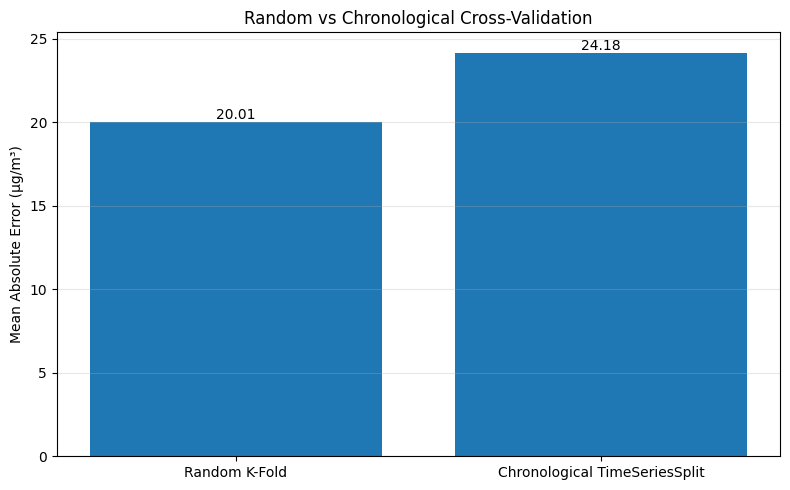

Chart saved to: /content/drive/MyDrive/PM25_project/figures/leakage_cv_comparison.png
File exists: True


In [66]:
# Calculate average MAE
random_mean = random_mae.mean()
time_mean = time_mae.mean()

# Create comparison chart
plt.figure(figsize=(8, 5))

methods = ["Random K-Fold", "Chronological TimeSeriesSplit"]
mae_values = [random_mean, time_mean]

bars = plt.bar(methods, mae_values)

plt.ylabel("Mean Absolute Error (µg/m³)")
plt.title("Random vs Chronological Cross-Validation")
plt.grid(axis="y", alpha=0.3)

# Display values above bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

# Save figure
chart_path = os.path.join(
    figure_path,
    "leakage_cv_comparison.png"
)

plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path)
print("File exists:", os.path.exists(chart_path))

### Random vs Chronological Cross-Validation

Random K-Fold cross-validation produced an average MAE of 20.01 µg/m³, whereas chronological TimeSeriesSplit produced an average MAE of 24.18 µg/m³. The random split gives a more optimistic performance estimate because observations from dates both before and after a validation observation can appear in the training folds. Since air pollution measurements on neighboring days are correlated, the model may indirectly benefit from information about nearby time periods. Chronological splitting provides a more realistic evaluation by training on earlier dates and evaluating on later dates. Therefore, chronological validation is more appropriate for estimating the model's performance in a next-day forecasting task.

DAY 16

In [67]:
import os

project_path = "/content/drive/MyDrive/PM25_project"
output_path = os.path.join(project_path, "outputs")
figure_path = os.path.join(project_path, "figures")

print("=== INTERPRETATION FIGURES ===")

for f in sorted(os.listdir(figure_path)):
    if any(word in f.lower() for word in
           ["lasso", "importance", "coefficient", "feature"]):
        print(f)

print("\n=== INTERPRETATION OUTPUTS ===")

for f in sorted(os.listdir(output_path)):
    if any(word in f.lower() for word in
           ["lasso", "importance", "coefficient", "feature"]):
        print(f)

=== INTERPRETATION FIGURES ===
lasso_coefficients.png
random_forest_feature_importance.png

=== INTERPRETATION OUTPUTS ===


In [68]:
# Find Lasso-related variables currently available
print("Lasso-related variables:")

for name in sorted(globals()):
    if "lasso" in name.lower():
        print(name, type(globals()[name]))

Lasso-related variables:
Lasso <class 'abc.ABCMeta'>
best_lasso <class 'sklearn.pipeline.Pipeline'>
fitted_lasso <class 'sklearn.linear_model._coordinate_descent.Lasso'>
lasso_mae <class 'float'>
lasso_param_grid <class 'dict'>
lasso_pipeline <class 'sklearn.pipeline.Pipeline'>
lasso_rmse <class 'numpy.float64'>
lasso_search <class 'sklearn.model_selection._search.GridSearchCV'>
lasso_val_pred <class 'numpy.ndarray'>
log_lasso_model <class 'sklearn.compose._target.TransformedTargetRegressor'>
log_lasso_pred <class 'numpy.ndarray'>


In [69]:
# Extract the fitted Lasso estimator
lasso_estimator = fitted_lasso

# Get feature names from the training feature dataframe
feature_names = X_train.columns

# Create coefficient table
lasso_coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": lasso_estimator.coef_
})

# Add absolute coefficient for ranking
lasso_coefficients["Absolute_Coefficient"] = (
    lasso_coefficients["Coefficient"].abs()
)

# Sort by absolute coefficient
lasso_coefficients = lasso_coefficients.sort_values(
    "Absolute_Coefficient",
    ascending=False
).reset_index(drop=True)

display(lasso_coefficients)

# Save results
lasso_output_path = os.path.join(
    output_path,
    "lasso_coefficients.csv"
)

lasso_coefficients.to_csv(
    lasso_output_path,
    index=False
)

print("\nSaved:", lasso_output_path)

ValueError: All arrays must be of the same length

In [70]:
print("Lasso pipeline steps:")
print(fitted_lasso)

print("\nCoefficient shape:")
print(fitted_lasso.coef_.shape)

print("\nOriginal X_train shape:")
print(X_train.shape)

print("\nPipeline steps:")
print(fitted_lasso.named_steps.keys())

Lasso pipeline steps:
Lasso(alpha=1, max_iter=20000, random_state=42)

Coefficient shape:
(22,)

Original X_train shape:
(7751, 16)

Pipeline steps:


AttributeError: 'Lasso' object has no attribute 'named_steps'

In [71]:
print("Variables containing X or feature:")

for name in sorted(globals()):
    if name.lower().startswith("x") or "feature" in name.lower():
        obj = globals()[name]

        if hasattr(obj, "shape"):
            print(name, "shape:", obj.shape)


Variables containing X or feature:
X_train shape: (7751, 16)
X_train_cls shape: (7751, 17)
X_val shape: (2188, 17)
X_val_cls shape: (2188, 17)
feature_names shape: (16,)
top_features shape: (15, 2)


In [72]:
models_to_check = {
    "best_lasso": best_lasso,
    "lasso_pipeline": lasso_pipeline,
    "fitted_lasso": fitted_lasso,
    "lasso_search_best": lasso_search.best_estimator_
}

for name, model in models_to_check.items():
    print(f"\n--- {name} ---")
    print("Type:", type(model))

    if hasattr(model, "coef_"):
        print("Coefficient count:", len(model.coef_))

    if hasattr(model, "named_steps"):
        print("Pipeline steps:", model.named_steps.keys())

print("\nCurrent feature_names:")
print(feature_names)


--- best_lasso ---
Type: <class 'sklearn.pipeline.Pipeline'>
Pipeline steps: dict_keys(['preprocessor', 'model'])

--- lasso_pipeline ---
Type: <class 'sklearn.pipeline.Pipeline'>
Pipeline steps: dict_keys(['preprocessor', 'model'])

--- fitted_lasso ---
Type: <class 'sklearn.linear_model._coordinate_descent.Lasso'>
Coefficient count: 22

--- lasso_search_best ---
Type: <class 'sklearn.pipeline.Pipeline'>
Pipeline steps: dict_keys(['preprocessor', 'model'])

Current feature_names:
Index(['PM2.5', 'PM2.5_lag_1', 'PM2.5_lag_2', 'PM2.5_lag_3', 'PM2.5_lag_7',
       'PM2.5_roll_mean_3', 'PM2.5_roll_mean_7', 'NO', 'NO2', 'NOx', 'NH3',
       'CO', 'SO2', 'O3', 'Benzene', 'Toluene'],
      dtype='object')


In [73]:
# Extract the fitted preprocessing and Lasso model
preprocessor = best_lasso.named_steps["preprocessor"]
lasso_model = best_lasso.named_steps["model"]

# Get feature names after preprocessing
transformed_features = preprocessor.get_feature_names_out()

# Extract coefficients
coefficients = lasso_model.coef_

# Verify dimensions
print("Number of transformed features:", len(transformed_features))
print("Number of coefficients:", len(coefficients))

# Create coefficient table
lasso_coefficients = pd.DataFrame({
    "Feature": transformed_features,
    "Coefficient": coefficients
})

lasso_coefficients["Absolute_Coefficient"] = (
    lasso_coefficients["Coefficient"].abs()
)

lasso_coefficients = lasso_coefficients.sort_values(
    "Absolute_Coefficient",
    ascending=False
).reset_index(drop=True)

display(lasso_coefficients)

# Save results
lasso_output_path = os.path.join(
    output_path,
    "lasso_coefficients.csv"
)

lasso_coefficients.to_csv(lasso_output_path, index=False)

print("\nSaved:", lasso_output_path)

Number of transformed features: 22
Number of coefficients: 22


,Feature,Coefficient,Absolute_Coefficient
0,num__PM2.5,45.967499,45.967499
1,num__PM2.5_roll_mean_7,14.728201,14.728201
2,num__PM2.5_lag_7,4.566974,4.566974
3,num__PM2.5_lag_3,2.658754,2.658754
4,num__NO,2.007504,2.007504
5,num__NO2,0.839920,0.839920
6,num__PM2.5_lag_2,0.326270,0.326270
7,num__NOx,0.310158,0.310158
8,num__O3,0.217628,0.217628
9,num__PM2.5_lag_1,0.000000,0.000000



Saved: /content/drive/MyDrive/PM25_project/outputs/lasso_coefficients.csv


## Lasso Regression — Coefficient Interpretation

The fitted Lasso regression model retained 12 non-zero coefficients among the 22 transformed features.

The current-day PM2.5 concentration had the largest positive coefficient (45.97), followed by the seven-day rolling mean of PM2.5 (14.73). This indicates that recent pollution levels and historical trends provide strong predictive information for next-day PM2.5 concentration.

Other features with positive coefficients included NO (2.01), NO2 (0.84), NOx (0.31), and O3 (0.22).

Several features, including PM2.5 lag 1, PM2.5 rolling mean 3, NH3, CO, SO2, Benzene, Toluene, and all city indicator variables, had coefficients of zero or approximately zero.

This demonstrates the feature-selection property of L1 regularization, which can shrink less useful coefficients to zero. These results represent predictive relationships and should not be interpreted as evidence of causation.

*Note: Coefficients are interpreted on the transformed feature scale used by the preprocessing pipeline.*

In [74]:
print("Random Forest-related variables:")

for name in sorted(globals()):
    if "rf" in name.lower() or "forest" in name.lower():
        obj = globals()[name]

        print(
            name,
            type(obj),
            getattr(obj, "shape", "")
        )


Random Forest-related variables:
RandomForestClassifier <class 'abc.ABCMeta'> 
RandomForestRegressor <class 'abc.ABCMeta'> 
best_rf <class 'sklearn.pipeline.Pipeline'> 
perf_counter <class 'builtin_function_or_method'> 
rf_best_threshold <class 'float'> 
rf_cls_pipeline <class 'sklearn.pipeline.Pipeline'> 
rf_fitted_model <class 'sklearn.ensemble._forest.RandomForestRegressor'> 
rf_importance_df <class 'pandas.core.frame.DataFrame'> (22, 2)
rf_importance_path <class 'pathlib._local.PosixPath'> 
rf_mae <class 'float'> 
rf_param_grid <class 'dict'> 
rf_pipeline <class 'sklearn.pipeline.Pipeline'> 
rf_prediction_seconds <class 'float'> 
rf_rmse <class 'numpy.float64'> ()
rf_search <class 'sklearn.model_selection._search.GridSearchCV'> 
rf_threshold_df <class 'pandas.core.frame.DataFrame'> (9, 4)
rf_threshold_results <class 'list'> 
rf_training_seconds <class 'float'> 
rf_tuned_pred <class 'numpy.ndarray'> (2188,)
rf_val_pred <class 'numpy.ndarray'> (2188,)
rf_val_prob <class 'numpy.ndarra

In [75]:
# Display existing Random Forest feature importance
display(rf_importance_df)

# Save a clean copy
rf_importance_path = os.path.join(
    output_path,
    "random_forest_feature_importance.csv"
)

rf_importance_df.to_csv(rf_importance_path, index=False)

print("\nSaved:", rf_importance_path)

,Feature,Importance
0,num__PM2.5,0.893986
1,num__PM2.5_roll_mean_3,0.026583
2,num__PM2.5_roll_mean_7,0.015182
3,num__CO,0.010199
4,num__PM2.5_lag_3,0.009556
5,num__PM2.5_lag_7,0.007625
6,num__PM2.5_lag_1,0.006807
7,num__NO,0.004564
8,num__PM2.5_lag_2,0.004502
9,num__NO2,0.004437



Saved: /content/drive/MyDrive/PM25_project/outputs/random_forest_feature_importance.csv


## Random Forest — Feature Importance Interpretation

The Random Forest feature-importance analysis shows that current-day PM2.5 is the dominant predictive feature, with an importance value of approximately 0.894 (89.4%).

The next most important features are the three-day rolling mean of PM2.5 (0.0266) and the seven-day rolling mean (0.0152). CO also contributes to the model, with an importance value of 0.0102.

Historical PM2.5 measurements, including lag features, provide additional predictive information. However, their individual importance values are considerably smaller than that of current-day PM2.5.

City indicator variables have very low importance values in this fitted model.

Overall, the analysis suggests that recent PM2.5 concentration and its historical trends are the most useful features for predicting next-day PM2.5 in this dataset.

Feature importance represents predictive contribution and does not establish causal relationships.

## Project Limitations

1. **Missing data:** Several pollutant features contained substantial missing values. Some features were excluded, while missing values in selected features were handled through imputation.

2. **Limited geographical coverage:** The primary model was trained using six selected Indian cities. Its performance may differ in cities with different pollution characteristics.

3. **Limited test period:** The final test dataset covers January to July 2020 and does not represent a complete annual cycle.

4. **Sudden pollution variations:** The model may struggle with abrupt changes in pollution levels that are not adequately represented by historical measurements.

5. **Limited external information:** Weather and meteorological variables, such as wind speed, rainfall and temperature, were not included in the selected feature set.

6. **Feature dependence:** The strong importance of current-day PM2.5 indicates that the model relies heavily on recent pollution measurements. Prediction accuracy may be affected when these measurements are unavailable or unreliable.

7. **Generalization limitations:** Performance on unseen cities may differ from performance on the six cities used for model development.

## Project Conclusion

This project developed and evaluated machine learning models to predict next-day PM2.5 concentrations using historical pollution measurements from six Indian cities.

Multiple regression approaches were evaluated, and the Support Vector Regression (SVR) model was selected as the final regression model.

On the held-out test dataset, the final model achieved:

- **MAE:** 11.455 µg/m³
- **RMSE:** 18.647 µg/m³

The residual analysis showed a mean error of approximately -2.93 µg/m³, indicating a slight tendency toward overprediction.

The feature interpretation experiments using Lasso and Random Forest showed that current-day PM2.5 concentration was the strongest predictive feature. Historical PM2.5 measurements also provided useful information.

Error analysis revealed differences in prediction performance across cities and months. The model performed better in some cities than others, highlighting the challenges of developing a pooled model for locations with different pollution patterns.

Overall, this project demonstrates how historical air-quality measurements and machine learning can be used to estimate next-day PM2.5 concentrations. However, the results are limited by missing data, geographical coverage, the test period and the absence of some external factors such as meteorological information.

Future improvements could include incorporating weather variables, expanding geographical coverage and evaluating the model on longer test periods.

Step 12 — Prepare the final conclusion
Before writing the conclusion, I want you to answer one question:

What surprised you most about this project?

My observation is that current-day PM2.5 dominates both Lasso and Random Forest interpretation, while the Random Forest assigns it nearly 89.4% importance.

But I want your own observation too. It will make the final project conclusion more authentic.